# 03 · Feature analysis (train period only)

Screening of the point-in-time features built in Phase 5
(`features.transaction_features`, catalog in `docs/feature_catalog.md`).

- **Same scope as the EDA:** train period only, eventual labels (retrospective view).
- **Univariate only.** A feature that is weak alone can matter in combination, and two
  strong features can be redundant. Whether a feature *adds* value is decided by ablation in
  Phases 6-7, not here.
- Two screening numbers per feature:
  - **AUC**: plain univariate AUC (monotonic ranking; 0.5 = none, < 0.5 = inverse).
  - **binned AUC**: AUC after replacing values by the fraud rate of their quantile bin, with
    NULL as its own bin. Captures U-shapes and the information in "no history".

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudplatform.config import load_feature_config, load_splits
from fraudplatform.db import connect
from fraudplatform.eda import plots, stats
from fraudplatform.eda.data import load_features
from fraudplatform.features import catalog

plots.apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 80)

splits = load_splits()
feature_cfg = load_feature_config()
with connect() as conn:
    df = load_features(conn, splits.train.start, splits.train.end, include_leaky=True)
    build = conn.execute(
        "SELECT build_id, feature_set_version, rows, seconds, built_at "
        "FROM features.builds ORDER BY build_id DESC LIMIT 1"
    ).fetchone()
base_rate = df["is_fraud"].mean()
print(f"feature build {build[0]} (v{build[1]}): {build[2]:,} rows in {build[3]}s")
print(f"train rows: {len(df):,}   base rate: {base_rate:.3%}")

feature build 1 (v1.0.0): 2,852,459 rows in 757.9s
train rows: 1,344,750   base rate: 0.848%


## 1. Coverage

NULL is meaningful here: no device (card present), no history yet (first transaction of a
card or customer in the data), or no standard deviation (fewer than two past payments).

In [2]:
coverage = pd.DataFrame(
    {
        "group": [f.group for f in catalog.FEATURES],
        "kind": [f.kind for f in catalog.FEATURES],
        "null_share": [df[f.name].isna().mean() for f in catalog.FEATURES],
    },
    index=catalog.FEATURE_NAMES,
)
coverage[coverage["null_share"] > 0].style.format({"null_share": "{:.1%}"})

,group,kind,null_share
device_age_days,entity,numeric,42.6%
card_seconds_since_prev,card_velocity,numeric,2.5%
cust_seconds_since_prev,customer_behaviour,numeric,2.0%
amount_to_cust_median_90d,customer_behaviour,numeric,2.1%
amount_zscore_cust_90d,customer_behaviour,numeric,4.3%
device_new_for_customer,device,boolean,42.6%
device_txn_count_1h,device,numeric,42.6%
device_unique_cards_24h,device,numeric,42.6%
device_unique_customers_30d,device,numeric,42.6%
country_changed,geo,boolean,2.0%


## 2. Univariate screening

In [3]:
rows = []
for f in catalog.FEATURES:
    if f.kind == "categorical":
        rows.append(
            {
                "feature": f.name,
                "group": f.group,
                "auc": np.nan,
                "binned_auc": stats.binned_auc(
                    df[f.name].cat.codes.replace(-1, np.nan), df["is_fraud"]
                ),
                "cramers_v": stats.cramers_v(df[f.name], df["is_fraud"]),
            }
        )
    else:
        rows.append(
            {
                "feature": f.name,
                "group": f.group,
                "auc": stats.univariate_auc(df[f.name], df["is_fraud"]),
                "binned_auc": stats.binned_auc(df[f.name], df["is_fraud"]),
                "cramers_v": np.nan,
            }
        )
screen = pd.DataFrame(rows).sort_values("binned_auc", ascending=False).reset_index(drop=True)
screen.style.format({"auc": "{:.3f}", "binned_auc": "{:.3f}", "cramers_v": "{:.3f}"})

,feature,group,auc,binned_auc,cramers_v
0,device_age_days,entity,0.135,0.832,nan
1,merchant_fraud_rate_90d_smoothed,labels_as_of,0.824,0.820,nan
2,card_seconds_since_prev,card_velocity,0.221,0.808,nan
3,cust_seconds_since_prev,customer_behaviour,0.217,0.804,nan
4,merchant_category,transaction,nan,0.796,0.133
5,cross_border,transaction,0.789,0.789,nan
6,card_amount_sum_24h,card_velocity,0.771,0.777,nan
7,card_txn_count_24h,card_velocity,0.777,0.777,nan
8,cust_txn_count_24h,customer_behaviour,0.777,0.777,nan
9,amount_eur,transaction,0.703,0.774,nan


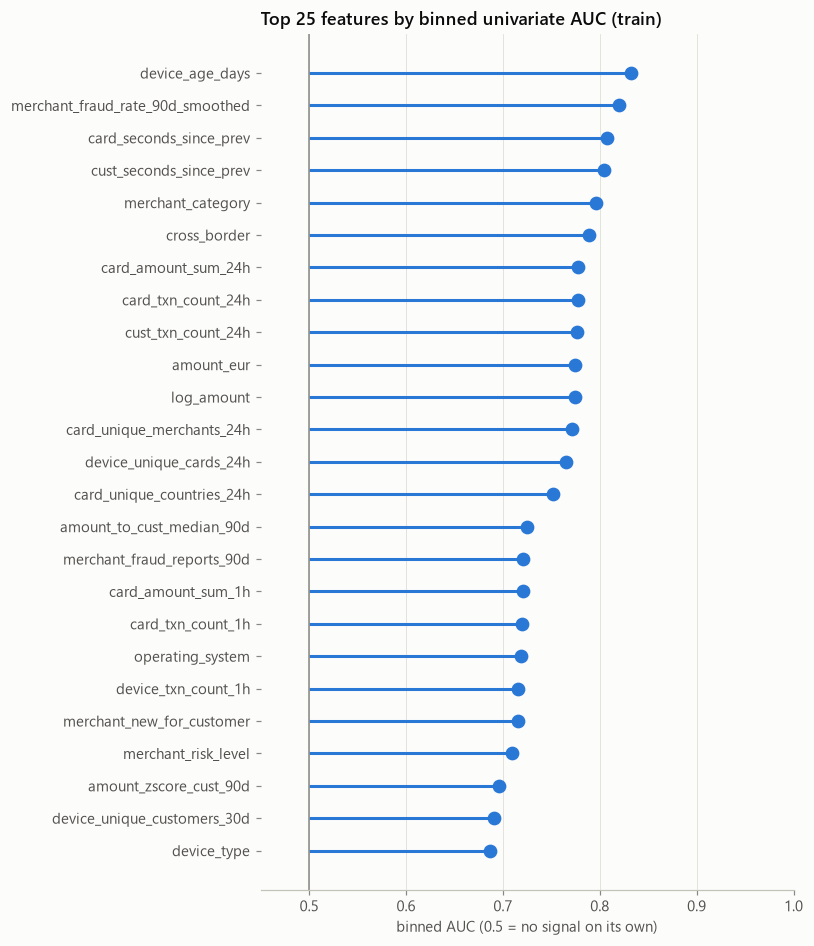

In [4]:
top = screen.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(top) + 1.2))
y = np.arange(len(top))
ax.hlines(y, 0.5, top["binned_auc"], color=plots.BLUE, linewidth=2)
ax.plot(top["binned_auc"], y, "o", color=plots.BLUE, markersize=8)
ax.set_yticks(y, top["feature"])
ax.grid(axis="y", visible=False)
ax.axvline(0.5, color=plots.MUTED, linewidth=1)
ax.set_xlim(0.45, 1.0)
ax.set_title("Top 25 features by binned univariate AUC (train)")
ax.set_xlabel("binned AUC (0.5 = no signal on its own)")
fig.tight_layout()
plots.save(fig, "binned_auc_top25", folder="features")
plt.show()

## 3. Fraud rate by value of key features

In [5]:
def bucket_rates(column: str, edges: list[float], labels: list[str]) -> pd.DataFrame:
    bucket = pd.cut(df[column], edges, labels=labels, right=False)
    bucket = bucket.cat.add_categories("NULL").fillna("NULL")
    return stats.rate_table(df.assign(bucket=bucket), "bucket").rename(columns={"bucket": column})


inf = np.inf
for column, edges, labels in [
    ("card_txn_count_1h", [0, 1, 2, 3, inf], ["0", "1", "2", "3+"]),
    ("card_micro_count_1h", [0, 1, 2, inf], ["0", "1", "2+"]),
    ("device_unique_cards_24h", [0, 1, 2, 3, inf], ["0", "1", "2", "3+"]),
    ("device_unique_customers_30d", [0, 1, 2, 3, 6, inf], ["0", "1", "2", "3-5", "6+"]),
    (
        "amount_to_cust_median_90d",
        [0, 0.5, 1, 2, 5, 10, inf],
        ["< 0.5x", "0.5-1x", "1-2x", "2-5x", "5-10x", "≥ 10x"],
    ),
    ("device_age_days", [0, 1 / 24, 1, 30, inf], ["< 1 h", "1 h - 1 d", "1-30 d", "> 30 d"]),
    ("card_prior_fraud_reports", [0, 1, inf], ["0", "≥ 1"]),
]:
    display(bucket_rates(column, edges, labels).round(4))

,card_txn_count_1h,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,0,1322785,6274,0.0047,0.0046,0.0049,0.5590
1,1,18889,3073,0.1627,0.1575,0.1680,19.1739
2,2,1542,1128,0.7315,0.7088,0.7530,86.2146
3,3+,1534,935,0.6095,0.5849,0.6336,71.8360


,card_micro_count_1h,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,0,1341931,10250,0.0076,0.0075,0.0078,0.9002
1,1,1119,204,0.1823,0.1608,0.2060,21.4860
2,2+,1700,956,0.5624,0.5387,0.5858,66.2773


,device_unique_cards_24h,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,0,681319,2476,0.0036,0.0035,0.0038,0.4283
1,1,88745,5286,0.0596,0.0580,0.0611,7.0200
2,2,1484,747,0.5034,0.4780,0.5288,59.3257
3,3+,532,491,0.9229,0.8971,0.9427,108.7742
4,NULL,572670,2410,0.0042,0.0040,0.0044,0.4960


,device_unique_customers_30d,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,0,130616,1165,0.0089,0.0084,0.0094,1.0512
1,1,637001,4707,0.0074,0.0072,0.0076,0.8709
2,2,1223,164,0.1341,0.1161,0.1543,15.8042
3,3-5,414,375,0.9058,0.8738,0.9303,106.7547
4,6+,2826,2589,0.9161,0.9053,0.9258,107.9732
5,NULL,572670,2410,0.0042,0.0040,0.0044,0.4960


,amount_to_cust_median_90d,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,< 0.5x,347389,1780,0.0051,0.0049,0.0054,0.6039
1,0.5-1x,316405,1138,0.0036,0.0034,0.0038,0.4239
2,1-2x,318767,1805,0.0057,0.0054,0.0059,0.6674
3,2-5x,218432,2654,0.0122,0.0117,0.0126,1.4320
4,5-10x,65745,1507,0.0229,0.0218,0.0241,2.7015
5,≥ 10x,50173,2407,0.0480,0.0461,0.0499,5.6541
6,NULL,27839,119,0.0043,0.0036,0.0051,0.5038


,device_age_days,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,< 1 h,45461,2896,0.0637,0.0615,0.0660,7.5078
1,1 h - 1 d,4334,1798,0.4149,0.4003,0.4296,48.8941
2,1-30 d,73817,2513,0.0340,0.0328,0.0354,4.0123
3,> 30 d,648468,1793,0.0028,0.0026,0.0029,0.3259
4,NULL,572670,2410,0.0042,0.0040,0.0044,0.4960


,card_prior_fraud_reports,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,0,1264884,10704,0.0085,0.0083,0.0086,0.9974
1,≥ 1,79866,706,0.0088,0.0082,0.0095,1.0418


In [6]:
flags = [
    "is_micro_amount",
    "is_night",
    "cross_border",
    "merchant_foreign",
    "is_card_present",
    "merchant_new_for_customer",
    "category_new_for_customer",
    "device_new_for_customer",
    "country_changed",
    "new_country_for_customer_180d",
    "impossible_travel",
]
flag_rows = []
for flag in flags:
    for value, label in ((1.0, "true"), (0.0, "false")):
        mask = df[flag] == value
        k, n = int(df.loc[mask, "is_fraud"].sum()), int(mask.sum())
        lo, hi = stats.wilson_interval(k, n)
        flag_rows.append(
            {
                "feature": flag,
                "value": label,
                "transactions": n,
                "fraud_rate": k / n if n else np.nan,
                "ci_low": lo,
                "ci_high": hi,
                "lift": (k / n) / base_rate if n else np.nan,
            }
        )
pd.DataFrame(flag_rows).style.format(
    {
        "transactions": "{:,}",
        "fraud_rate": "{:.2%}",
        "ci_low": "{:.2%}",
        "ci_high": "{:.2%}",
        "lift": "{:.2f}",
    }
)

,feature,value,transactions,fraud_rate,ci_low,ci_high,lift
0,is_micro_amount,true,"70,072",1.92%,1.82%,2.02%,2.26
1,is_micro_amount,false,"1,274,678",0.79%,0.77%,0.81%,0.93
2,is_night,true,"50,001",4.55%,4.37%,4.73%,5.36
3,is_night,false,"1,294,749",0.71%,0.69%,0.72%,0.83
4,cross_border,true,"62,145",11.38%,11.13%,11.63%,13.41
5,cross_border,false,"1,282,605",0.34%,0.33%,0.35%,0.40
6,merchant_foreign,true,"591,752",1.44%,1.41%,1.47%,1.69
7,merchant_foreign,false,"752,998",0.39%,0.37%,0.40%,0.46
8,is_card_present,true,"568,774",0.41%,0.39%,0.43%,0.48
9,is_card_present,false,"775,976",1.17%,1.15%,1.19%,1.38


## 4. Warm-up: history starts on 2024-07-01 for everybody

Novelty and profile features need history. At the start of the data every merchant,
category and country looks "new" because earlier history does not exist in the extract,
not because the customer's behaviour is new. This bias fades as history accumulates.

,merchant_new,category_new,country_new_180d,no_90d_history
month,,,,
2024-07,76.8%,63.0%,22.7%,21.1%
2024-08,55.1%,33.8%,3.7%,1.5%
2024-09,45.5%,23.1%,2.5%,0.4%
2024-10,40.1%,17.8%,2.4%,0.3%
2024-11,35.5%,14.2%,2.2%,0.3%
2024-12,32.9%,11.9%,2.1%,0.3%
2025-01,30.4%,10.0%,2.2%,0.3%
2025-02,28.5%,9.0%,2.2%,0.3%
2025-03,27.2%,8.0%,2.1%,0.3%


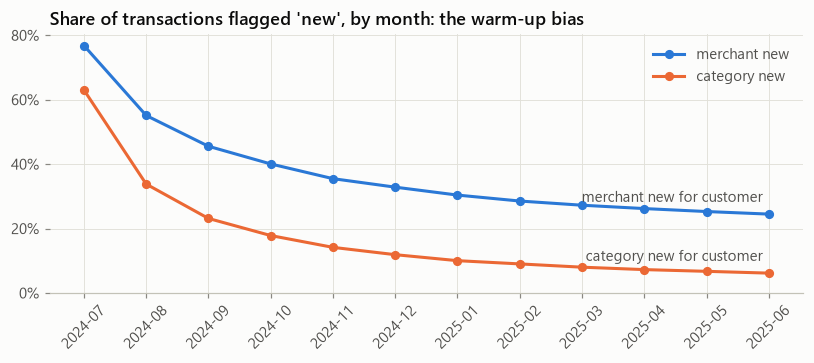

In [7]:
df["month"] = df["ts"].dt.strftime("%Y-%m")
warmup = df.groupby("month").agg(
    merchant_new=("merchant_new_for_customer", "mean"),
    category_new=("category_new_for_customer", "mean"),
    country_new_180d=("new_country_for_customer_180d", "mean"),
    no_90d_history=("cust_txn_count_90d", lambda s: (s == 0).mean()),
)
display(warmup.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
xs = np.arange(len(warmup))
ax.plot(xs, warmup["merchant_new"], color=plots.BLUE, marker="o", markersize=5)
ax.annotate(
    "merchant new for customer",
    (xs[-1], warmup["merchant_new"].iloc[-1]),
    xytext=(-4, 8),
    textcoords="offset points",
    ha="right",
    color=plots.INK_SECONDARY,
)
ax.plot(xs, warmup["category_new"], color=plots.ORANGE, marker="o", markersize=5)
ax.annotate(
    "category new for customer",
    (xs[-1], warmup["category_new"].iloc[-1]),
    xytext=(-4, 8),
    textcoords="offset points",
    ha="right",
    color=plots.INK_SECONDARY,
)
ax.set_xticks(xs, warmup.index, rotation=45)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_ylim(bottom=0)
ax.set_title("Share of transactions flagged 'new', by month: the warm-up bias")
ax.legend(["merchant new", "category new"], loc="upper right")
fig.tight_layout()
plots.save(fig, "warmup_novelty", folder="features")
plt.show()

## 5. Leaky vs point-in-time features

Each deliberately leaky feature next to its clean counterpart (same idea, computed with
information that would not exist at decision time). The time-travel test proves they leak;
here we see how much better they *look*.

In [8]:
leak_rows = []
for leaky, clean in catalog.LEAKY_FEATURES.items():
    leak_rows.append(
        {
            "clean_feature": clean,
            "clean_binned_auc": stats.binned_auc(df[clean], df["is_fraud"]),
            "leaky_feature": leaky,
            "leaky_binned_auc": stats.binned_auc(df[leaky], df["is_fraud"]),
        }
    )
leak = pd.DataFrame(leak_rows)
leak["inflation"] = leak["leaky_binned_auc"] - leak["clean_binned_auc"]
leak.style.format(
    {"clean_binned_auc": "{:.3f}", "leaky_binned_auc": "{:.3f}", "inflation": "{:+.3f}"}
)

,clean_feature,clean_binned_auc,leaky_feature,leaky_binned_auc,inflation
0,card_txn_count_24h,0.777,leaky_card_txn_count_24h_centered,0.899,+0.122
1,amount_to_cust_median_90d,0.725,leaky_cust_amount_median_alltime,0.774,+0.049
2,device_unique_customers_30d,0.691,leaky_device_unique_customers_alltime,0.715,+0.025
3,card_prior_fraud_reports,0.507,leaky_card_prior_fraud_naive,0.789,+0.282
4,merchant_fraud_rate_90d_smoothed,0.820,leaky_merchant_fraud_rate_alltime,0.883,+0.063


## 6. Redundancy between numeric features

Pairs with |Spearman ρ| ≥ 0.85: they carry largely the same information.

In [9]:
numeric = [c for c in catalog.NUMERIC + catalog.BOOLEAN]
rho = df[numeric].corr(method="spearman")
pairs = (
    rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
pairs[pairs["spearman"].abs() >= 0.85].sort_values("spearman", key=abs, ascending=False).round(3)

,feature_a,feature_b,spearman
1,amount_eur,log_amount,1.000
311,card_txn_count_1h,card_amount_sum_1h,1.000
1101,distance_from_prev_km,implied_speed_kmh,1.000
1115,distance_from_prev_km,country_changed,1.000
1158,implied_speed_kmh,country_changed,1.000
358,card_txn_count_24h,card_unique_merchants_24h,1.000
617,card_unique_merchants_24h,card_unique_countries_24h,0.998
359,card_txn_count_24h,card_unique_countries_24h,0.998
487,card_amount_sum_24h,card_unique_merchants_24h,0.994
488,card_amount_sum_24h,card_unique_countries_24h,0.994


## 7. Findings

Full write-up with every number from this run:
[`reports/features/feature_findings.md`](../reports/features/feature_findings.md). In short:

- Strongest on their own: device age (new devices), merchant fraud rate as known at ts,
  time since the card's previous use, merchant category, cross-border, 24 h card velocity.
- Card velocity (H1) and device sharing (H3) behave as expected; relative amount (H2) is
  not better than the raw amount on its own.
- `card_prior_fraud_reports` is useless point-in-time (reports arrive too late) while its
  naive leaky version looks excellent: +0.28 binned AUC of pure leakage.
- Every leaky variant looks better than its clean counterpart.
- Warm-up bias: novelty features are inflated in the first months; train from 2024-10-01.